# Lab: Rasterio — część B
**Gdzie w Opolu jest najwięcej zieleni?** Dwa pasma Sentinel-2 L2A z 6.10.2026: B04 (Red) i B08 (NIR).

Dane w `dane/` (TIFF-y), dzielnice z części A (`dane/opole_districts.geojson`).

## B1. Raster, GeoTIFF i NDVI — podstawy

* **Raster** = siatka pikseli (tablica NumPy) + **georeferencja**: CRS i transformacja afiniczna, która mówi, gdzie na Ziemi leży piksel (wiersz, kolumna).
* **GeoTIFF** = zwykły TIFF z dopisanymi tagami georeferencji. Jeden plik może mieć wiele pasm.
* **nodata** = wartość oznaczająca „brak danych” (poza zasięgiem sceny, chmura itp.). Trzeba ją wykluczyć z obliczeń, tak jak -999 w części A.
* **NDVI** = (NIR − Red) / (NIR + Red), zakres −1…1. Zdrowa roślinność mocno odbija bliską podczerwień (B08)
  i pochłania czerwień (B04), więc ma NDVI ≈ 0,5–0,9. Zabudowa i gleba ≈ 0–0,2, woda < 0.

In [1]:
import numpy as np
import rasterio
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

B04 = "dane/S2_L2A_2026-10-06_B04.tiff"
B08 = "dane/S2_L2A_2026-10-06_B08.tiff"
print("rasterio", rasterio.__version__, "| GDAL", rasterio.__gdal_version__)

rasterio 1.5.2 | GDAL 3.12.2


## B2. Otwarcie pliku i metadane

In [2]:
with rasterio.open(B04) as src:
    print("driver   :", src.driver)
    print("size     :", src.width, "x", src.height, "px,", src.count, "band(s)")
    print("dtype    :", src.dtypes)
    print("crs      :", src.crs)
    print("nodata   :", src.nodata)
    print("bounds   :", src.bounds)
    print("res      :", src.res)
    print("transform:", tuple(src.transform)[:6])

driver   : GTiff
size     : 1995 x 1426 px, 1 band(s)
dtype    : ('float32',)
crs      : EPSG:4326
nodata   : None
bounds   : BoundingBox(left=17.83630213295036, bottom=50.62517997957092, right=18.015516610489424, top=50.70634951703124)
res      : (8.983181831531955e-05, 5.692113426389829e-05)
transform: (8.983181831531955e-05, 0.0, 17.83630213295036, 0.0, -5.692113426389829e-05, 50.70634951703124)


In [3]:
# porównanie metadanych obu pasm - muszą mieć tę samą siatkę, inaczej piksele się nie pokryją
with rasterio.open(B04) as r, rasterio.open(B08) as n:
    same = (r.crs == n.crs) and (r.transform == n.transform) and (r.shape == n.shape)
    print("ta sama siatka:", same)

ta sama siatka: True


In [4]:
# ile metrów ma piksel? res jest w stopniach (EPSG:4326)
with rasterio.open(B04) as src:
    dx_deg, dy_deg = src.res
    lat0 = (src.bounds.top + src.bounds.bottom) / 2
    dx_m = dx_deg * 111_320 * np.cos(np.radians(lat0))
    dy_m = dy_deg * 110_574
print(f"piksel: {dx_deg:.3e}° x {dy_deg:.3e}°  ~  {dx_m:.2f} m x {dy_m:.2f} m")

piksel: 8.983e-05° x 5.692e-05°  ~  6.34 m x 6.29 m


💡 Plik jest w **EPSG:4326**, piksel ma ok. 0,0000898° × 0,0000569°, czyli ok. **6,3 m × 6,3 m**. W stopniach piksel jest
„prostokątny”, w metrach prawie kwadratowy, bo stopień długości w Opolu jest krótszy. Natywna rozdzielczość B04/B08
to 10 m, więc eksport z Copernicus Browser został przepróbkowany. Szczegółów mniejszych niż 10 m tu nie ma, mimo drobniejszych pikseli.

`nodata = None`: plik nie deklaruje brakujących danych. Typ to `float32`: to już współczynnik odbicia (0–1), a nie surowe DN 0–10000.

## B3. Piksel ↔ współrzędne

Transformacja afiniczna to 6 liczb `(a, b, c, d, e, f)`:
`x = a·col + b·row + c`, `y = d·col + e·row + f`.
`c, f` to lewy górny róg, `a` szerokość piksela, `e` wysokość (ujemna, bo wiersze rosną w dół, a y w górę).

In [5]:
rynek_lon, rynek_lat = 17.9226, 50.6681

with rasterio.open(B04) as r4, rasterio.open(B08) as r8:
    row, col = r4.index(rynek_lon, rynek_lat)          # współrzędne -> (wiersz, kolumna)
    x, y = r4.xy(row, col)                             # (wiersz, kolumna) -> środek piksela
    red = r4.read(1)[row, col]
    nir = r8.read(1)[row, col]
    print(f"Rynek -> piksel (row={row}, col={col}), środek piksela: ({x:.6f}, {y:.6f})")
    print(f"B04={red:.4f}  B08={nir:.4f}  NDVI={(nir - red) / (nir + red):.3f}")

    # to samo ręcznie z transformacji
    t = r4.transform
    print("ręcznie:", ~t * (rynek_lon, rynek_lat))   # (col, row) jako float

Rynek -> piksel (row=671, col=960), środek piksela: (17.922586, 50.668127)
B04=0.0561  B08=0.0650  NDVI=0.073
ręcznie: (960.660361418064, 671.9739078618586)


💡 Rynek ma NDVI ≈ 0,07: bruk i dachy. `index()` zwraca wiersz/kolumnę zaokrągloną w dół, a `~transform` pokazuje,
że punkt leży w ok. 66% szerokości piksela 960. `xy()` domyślnie zwraca **środek** piksela, nie róg.

Klikalna mapa. Kliknięcie w mapę pokazuje lon/lat, a w markerach jest wartość NDVI odczytana z piksela.
Nakładka to PNG wyrenderowany z rastra w EPSG:4326. Leaflet rysuje w EPSG:3857, ale na obszarze 8 × 13 km różnica jest pomijalna.


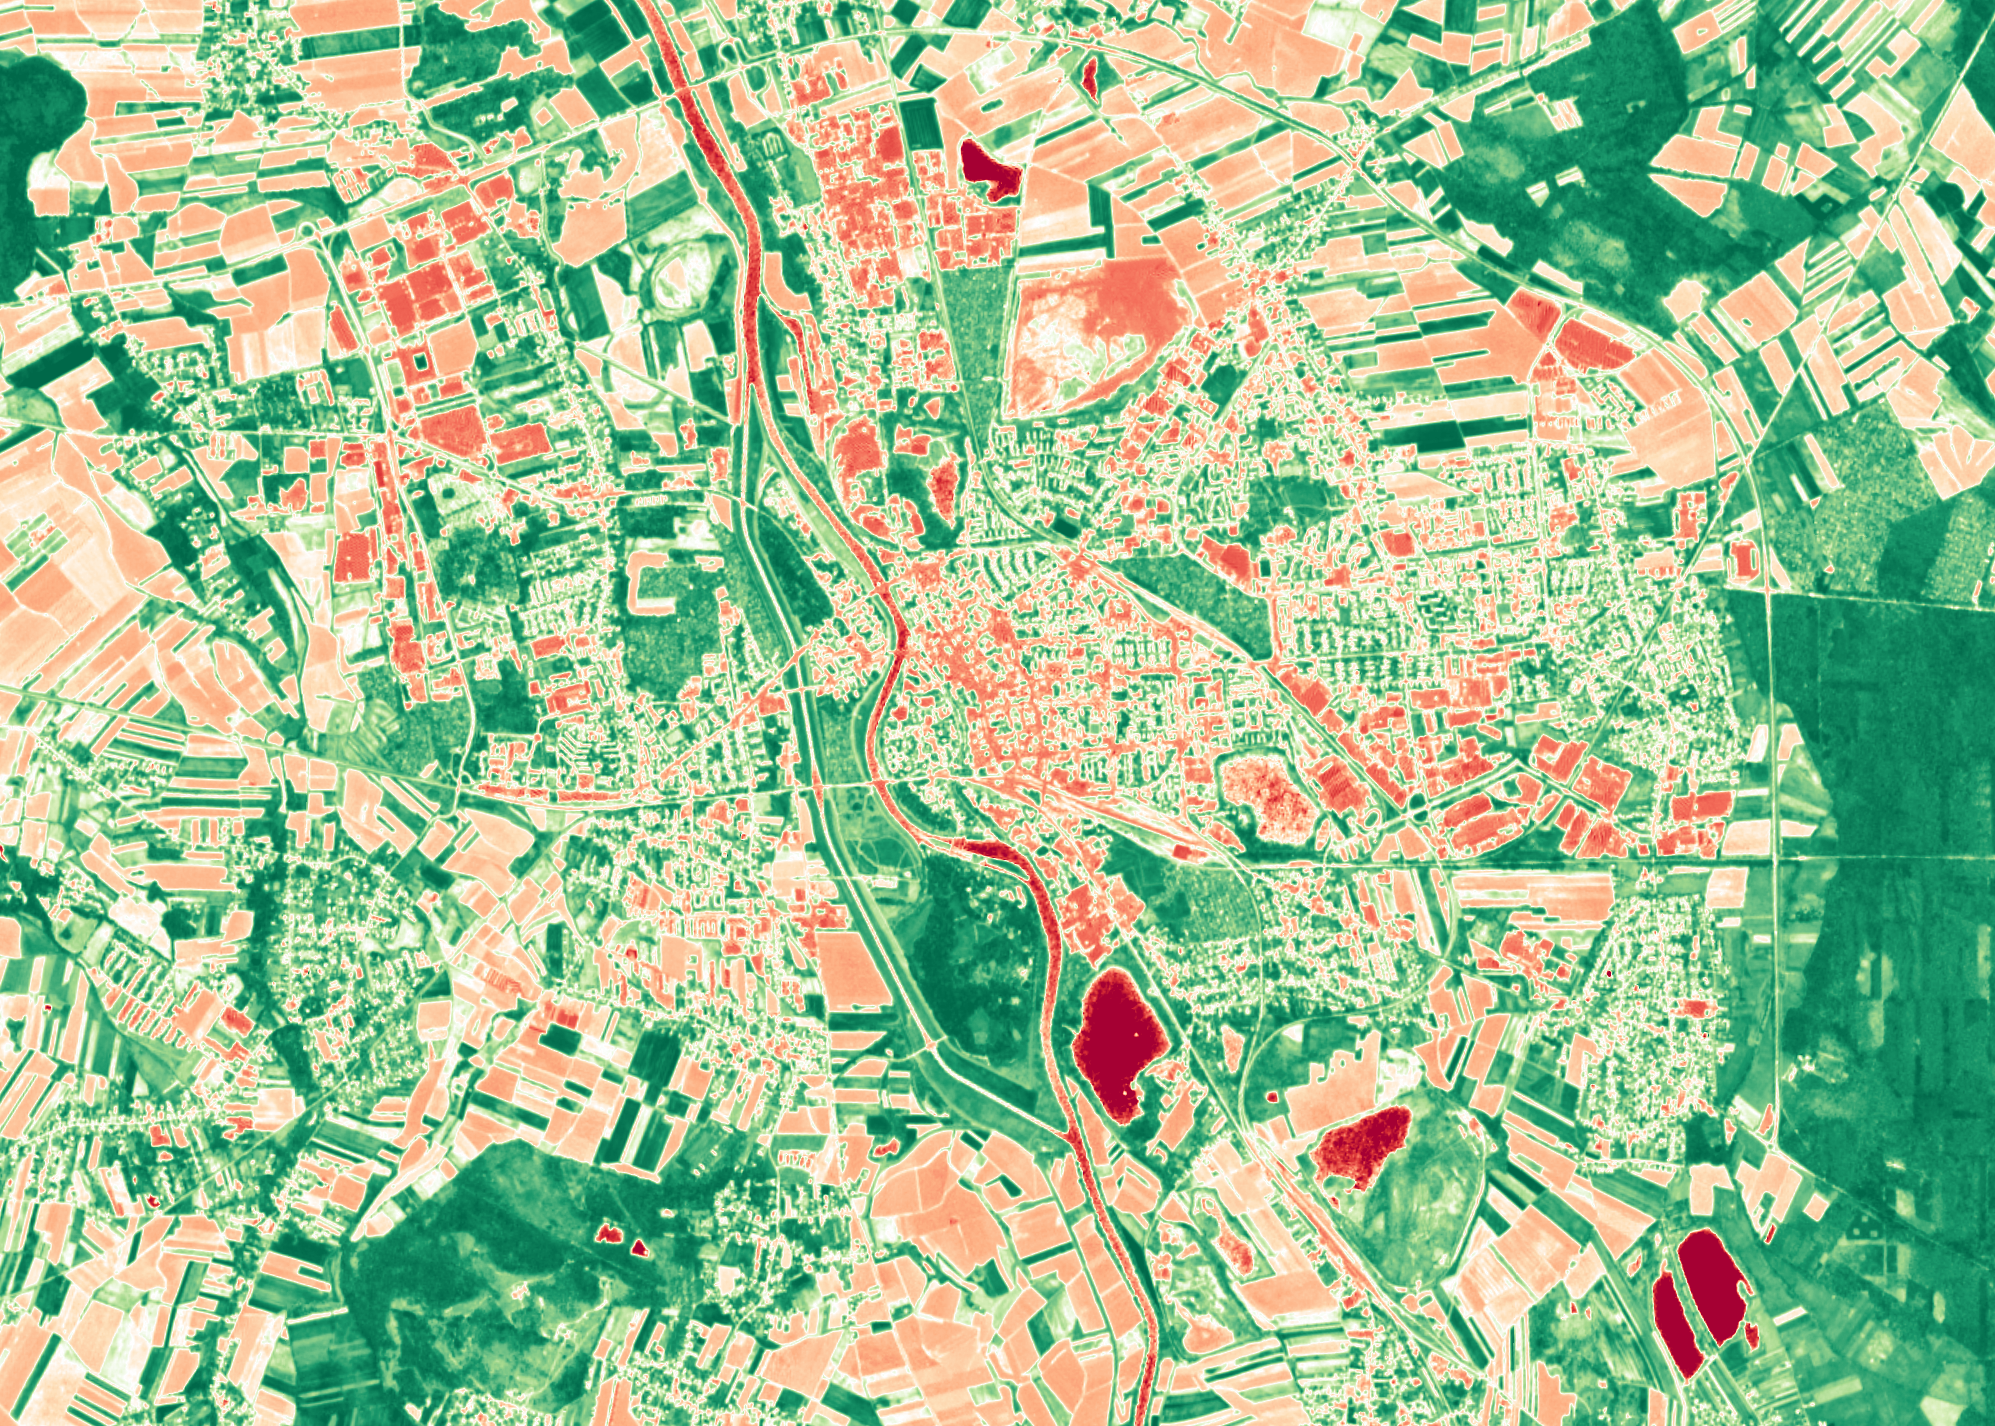

In [6]:
import folium
from matplotlib import colormaps

with rasterio.open(B04) as r4, rasterio.open(B08) as r8:
    red4, nir4 = r4.read(1), r8.read(1)
    b = r4.bounds
    with np.errstate(divide="ignore", invalid="ignore"):
        ndvi4326 = (nir4 - red4) / (nir4 + red4)

rgba = colormaps["RdYlGn"]((np.clip(ndvi4326, -0.2, 0.9) + 0.2) / 1.1)
fm = folium.Map(location=[rynek_lat, rynek_lon], zoom_start=12, tiles="OpenStreetMap")
folium.raster_layers.ImageOverlay(rgba, bounds=[[b.bottom, b.left], [b.top, b.right]], opacity=0.6, name="NDVI").add_to(fm)

pts = {"Rynek": (17.9226, 50.6681), "Wyspa Bolko": (17.9235, 50.6545), "Akwen (dawny kamieniołom)": (17.9366, 50.6469)}
with rasterio.open(B04) as r4:
    for name, (lon, lat) in pts.items():
        rr, cc = r4.index(lon, lat)
        folium.Marker([lat, lon], popup=f"{name}: piksel ({rr}, {cc}), NDVI = {ndvi4326[rr, cc]:.2f}").add_to(fm)
folium.LatLngPopup().add_to(fm)
fm

## B4. Odczyt pasm, statystyki, histogramy

In [7]:
with rasterio.open(B04) as r4, rasterio.open(B08) as r8:
    red = r4.read(1)
    nir = r8.read(1)

for name, a in [("B04 red", red), ("B08 nir", nir)]:
    print(f"{name}: shape={a.shape} dtype={a.dtype} min={a.min():.4f} max={a.max():.4f} "
          f"mean={a.mean():.4f} NaN={np.isnan(a).sum()} >1: {(a > 1).sum()} px")

B04 red: shape=(1426, 1995) dtype=float32 min=0.0031 max=1.5873 mean=0.0714 NaN=0 >1: 16 px
B08 nir: shape=(1426, 1995) dtype=float32 min=0.0030 max=1.5323 mean=0.2179 NaN=0 >1: 21 px


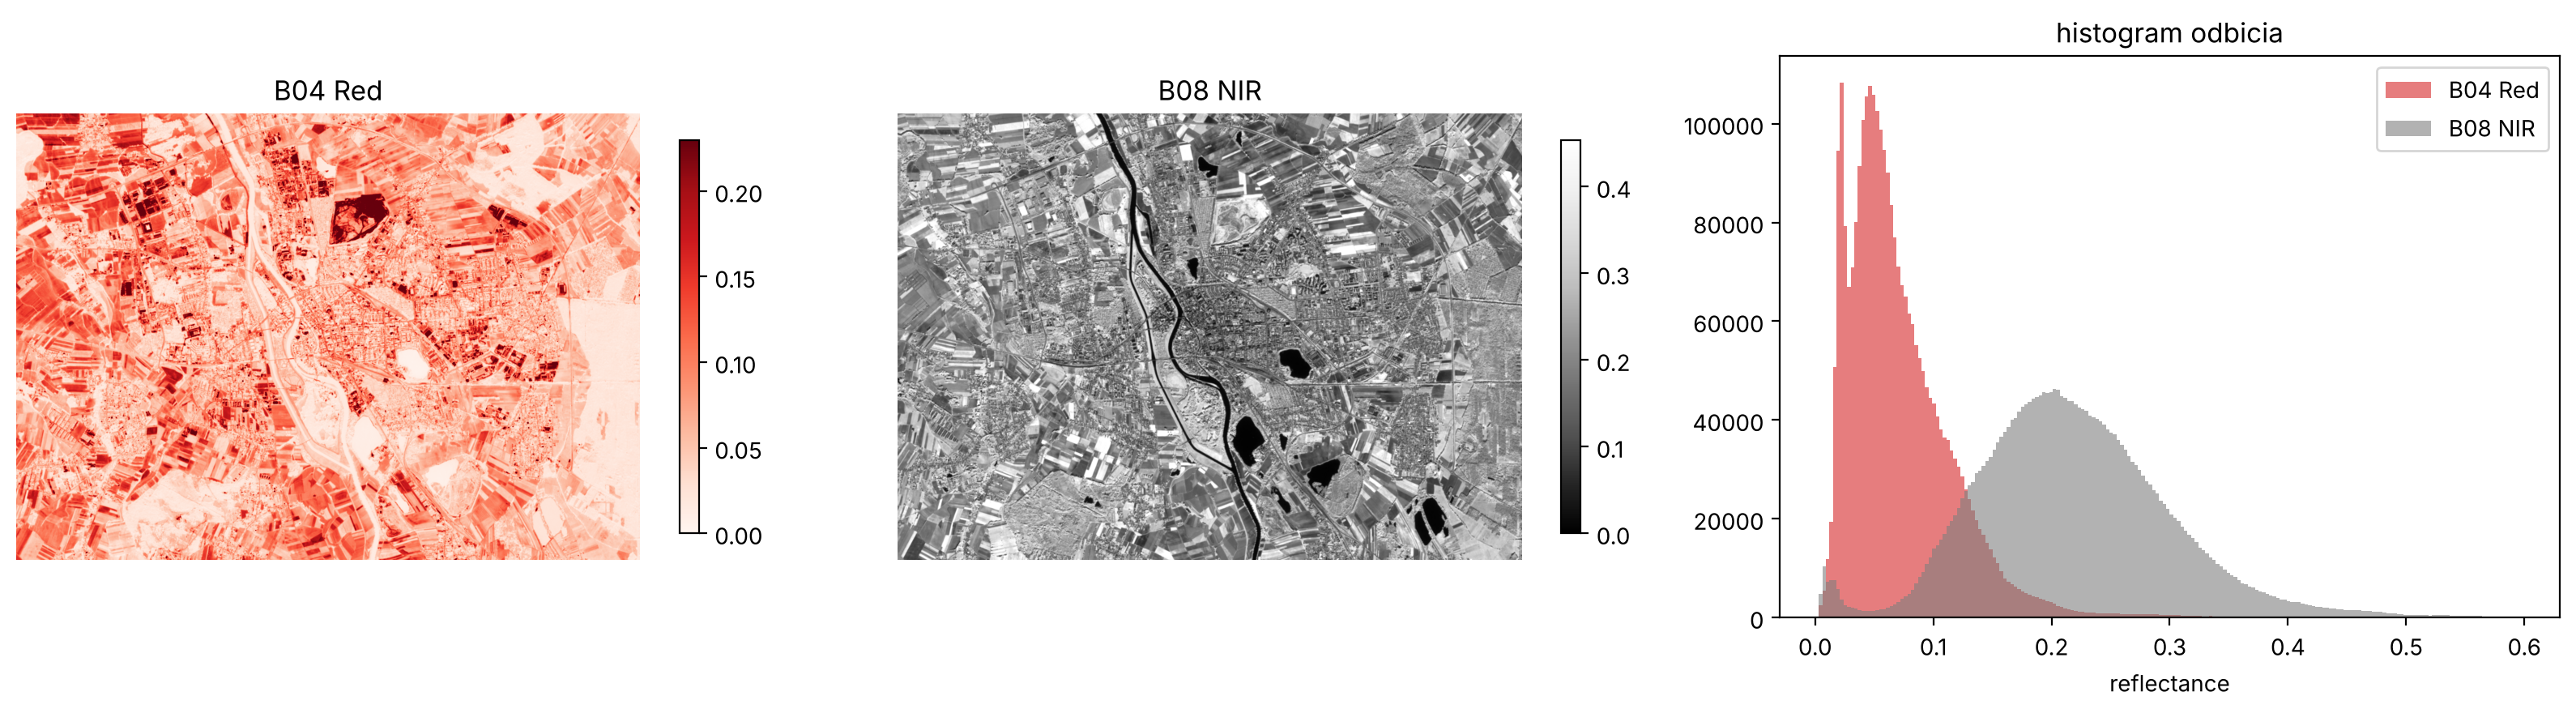

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, a, title, cmap in [(axes[0], red, "B04 Red", "Reds"), (axes[1], nir, "B08 NIR", "Greys_r")]:
    im = ax.imshow(a, cmap=cmap, vmin=0, vmax=np.percentile(a, 99))
    ax.set_title(title); ax.set_axis_off(); fig.colorbar(im, ax=ax, shrink=0.7)
axes[2].hist(red.ravel(), bins=200, range=(0, 0.6), alpha=0.6, label="B04 Red", color="tab:red")
axes[2].hist(nir.ravel(), bins=200, range=(0, 0.6), alpha=0.6, label="B08 NIR", color="tab:gray")
axes[2].set_title("histogram odbicia"); axes[2].set_xlabel("reflectance"); axes[2].legend()
plt.tight_layout(); plt.show()

💡 W NIR roślinność jest jasna, a w Red ciemna. Histogram NIR ma wyraźny „ogon” w prawo (pola, lasy, parki).
Pojedyncze piksele > 1 to bardzo jasne powierzchnie (dachy, odblaski). Fizycznie to możliwe w L2A, ale jest ich garstka
i nie psują średnich. Braków (NaN) w surowych pasmach nie ma.

## B5. Wspólna siatka w metrach (`reproject`)

Liczenie powierzchni w hektarach i nakładanie poligonów dzielnic (EPSG:2180) wymaga rastra w tym samym, metrycznym CRS.
Ustalamy siatkę docelową 10 m (natywna rozdzielczość B04/B08) i przeliczamy na nią oba pasma.

In [9]:
from rasterio.warp import calculate_default_transform, reproject, Resampling

DST_CRS = "EPSG:2180"
RES = 10   # m

with rasterio.open(B04) as src:
    dst_transform, dst_w, dst_h = calculate_default_transform(
        src.crs, DST_CRS, src.width, src.height, *src.bounds, resolution=RES)
print(dst_transform)
print("nowa siatka:", dst_w, "x", dst_h, "px")

def to_grid(path):
    out = np.full((dst_h, dst_w), np.nan, dtype="float32")   # NaN = poza sceną
    with rasterio.open(path) as src:
        reproject(
            source=rasterio.band(src, 1), destination=out,
            src_transform=src.transform, src_crs=src.crs,
            dst_transform=dst_transform, dst_crs=DST_CRS,
            dst_nodata=np.nan, resampling=Resampling.bilinear,
        )
    return out

red_m = to_grid(B04)
nir_m = to_grid(B08)
print(f"NaN po reprojekcji: {np.isnan(red_m).mean():.1%}")

| 10.00, 0.00, 417713.45|
| 0.00,-10.00, 316130.48|
| 0.00, 0.00, 1.00|
nowa siatka: 1279 x 921 px


NaN po reprojekcji: 3.0%


💡 Po reprojekcji ok. 3% pikseli to NaN. To nie błąd: prostokąt w stopniach po przeliczeniu na PUWG 1992 jest lekko obrócony,
więc w rogach nowej, prostokątnej siatki nie ma danych. Właśnie dlatego ustawiamy `dst_nodata=np.nan`, a nie zostawiamy zer.

🤔 **Dlaczego `bilinear`, a nie `nearest`?** Odbicie jest wielkością ciągłą, więc interpolacja daje gładszy i wierniejszy wynik.
Dla rastrów **kategorii** (klasy, maski) używamy `nearest`, bo średnia z „lasu” i „wody” to bzdura.

## B6. NDVI = (B08 − B04) / (B08 + B04)

In [10]:
with np.errstate(divide="ignore", invalid="ignore"):
    ndvi = (nir_m - red_m) / (nir_m + red_m)
ndvi[(nir_m + red_m) == 0] = np.nan          # dzielenie przez zero -> brak danych

print(f"NDVI: min={np.nanmin(ndvi):.3f} max={np.nanmax(ndvi):.3f} mean={np.nanmean(ndvi):.3f} "
      f"median={np.nanmedian(ndvi):.3f}")

NDVI: min=-0.586 max=0.934 mean=0.490 median=0.513


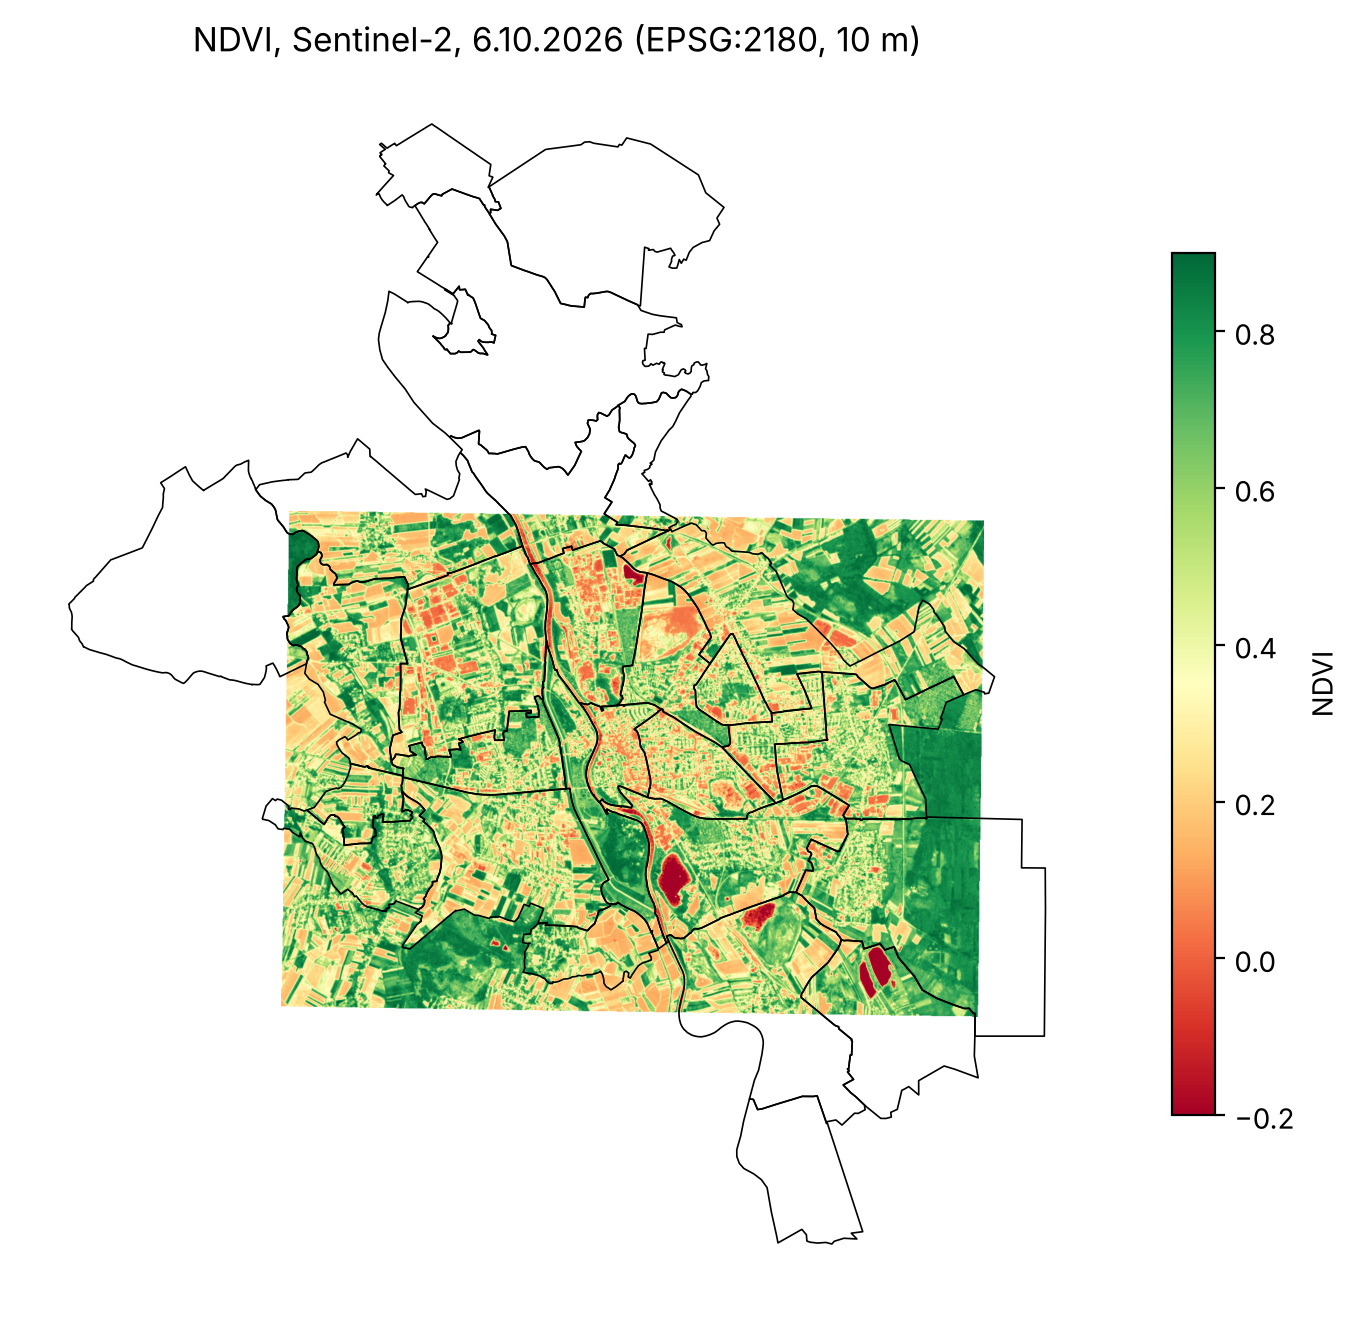

In [11]:
from rasterio.plot import plotting_extent

districts = gpd.read_file("dane/opole_districts.geojson").to_crs(DST_CRS)
extent = plotting_extent(ndvi, dst_transform)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.9, extent=extent)
districts.boundary.plot(ax=ax, color="black", linewidth=0.6)
ax.set_title("NDVI, Sentinel-2, 6.10.2026 (EPSG:2180, 10 m)")
fig.colorbar(im, ax=ax, shrink=0.7, label="NDVI")
ax.set_axis_off(); plt.show()

💡 Odra i stawy są czerwone (NDVI < 0), centrum i osiedla żółto-pomarańczowe, a wyspa Bolko, lasy i pola wyraźnie zielone.

🤔 **Dlaczego najpierw `float`, a potem dzielenie?** Gdyby pasma były w `uint16` (surowe DN), odejmowanie `nir - red`
przy `red > nir` „zawinęłoby się” do 65 000+. Tutaj dane są już `float32`, ale przy surowych L2A trzeba zrobić `.astype("float32")`.

## B7. Klasyfikacja i powierzchnie w hektarach

In [12]:
bins   = [-1, 0.0, 0.2, 0.5, 1.0001]
labels = ["woda", "zabudowa / odkryta gleba", "rzadka roślinność", "gęsta roślinność"]
colors = ["#2b83ba", "#bdbdbd", "#c2e699", "#238443"]

valid = ~np.isnan(ndvi)
classes = np.zeros(ndvi.shape, dtype="uint8")                 # 0 = nodata
classes[valid] = np.digitize(ndvi[valid], bins)                 # 1..4

px_ha = RES * RES / 10_000                                      # 10 m x 10 m = 0,01 ha
area = pd.DataFrame({
    "klasa": labels,
    "ha": [(classes == k).sum() * px_ha for k in range(1, 5)],
})
area["%"] = (100 * area["ha"] / area["ha"].sum()).round(1)
area["ha"] = area["ha"].round(1)
area

,klasa,ha,%
0,woda,126.3,1.1
1,zabudowa / odkryta gleba,1746.4,15.3
2,rzadka roślinność,3693.2,32.3
3,gęsta roślinność,5860.8,51.3


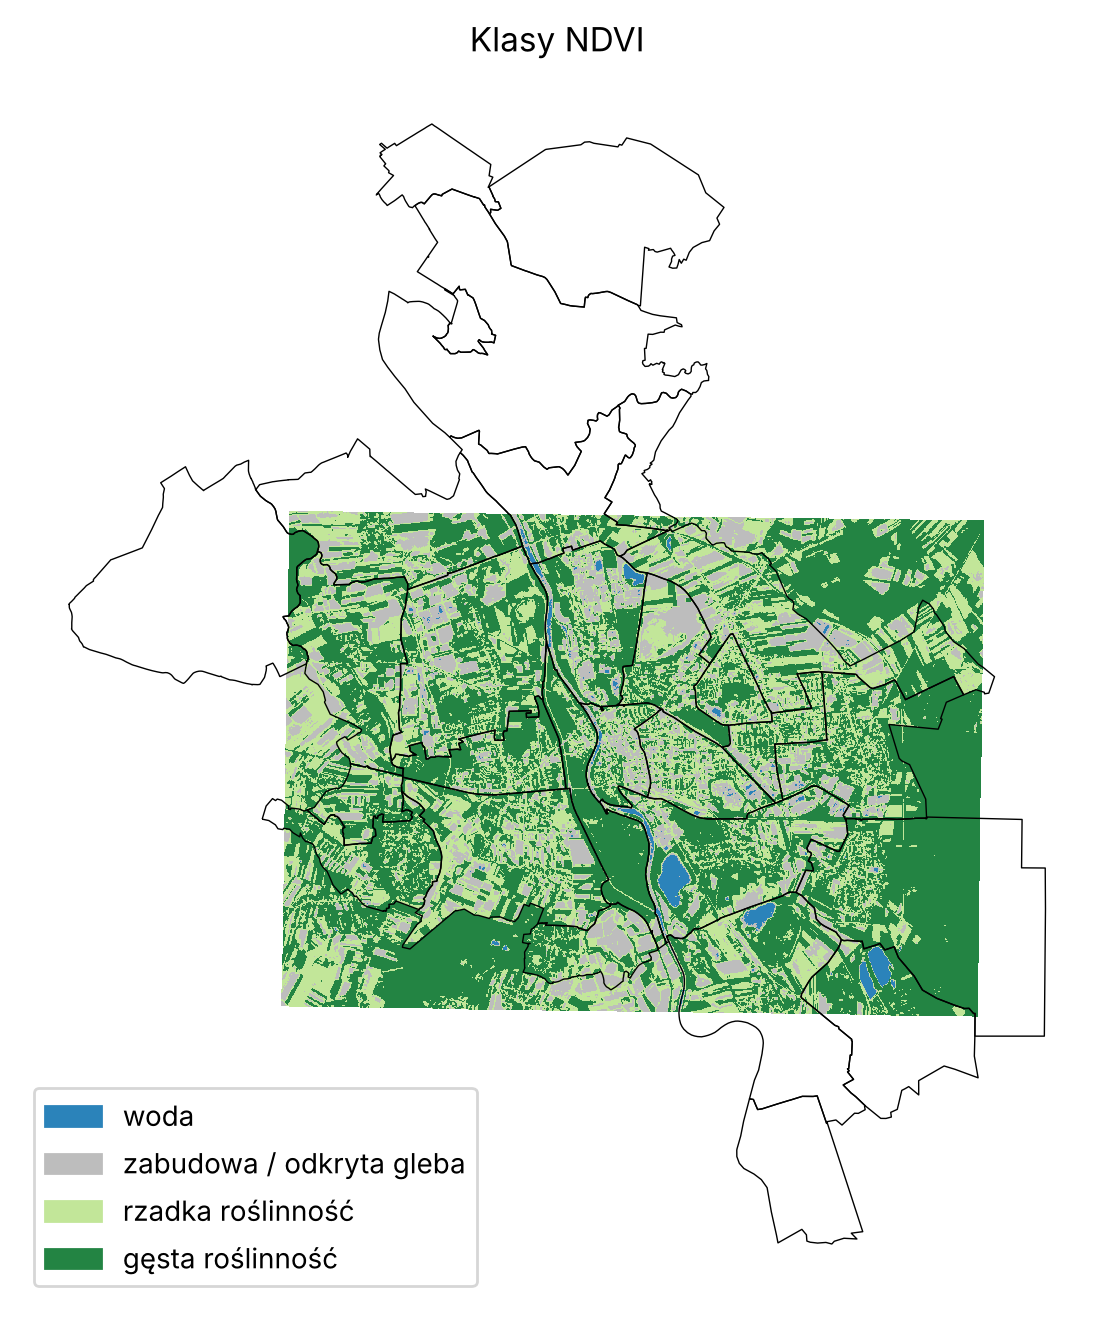

In [13]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(np.ma.masked_equal(classes, 0), cmap=ListedColormap(colors), vmin=1, vmax=4,
          extent=extent, interpolation="nearest")
districts.boundary.plot(ax=ax, color="black", linewidth=0.5)
ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(colors, labels)], loc="lower left")
ax.set_title("Klasy NDVI"); ax.set_axis_off(); plt.show()

💡 Powierzchnię liczymy jako **liczba pikseli × powierzchnia piksela**, a to ma sens tylko w układzie metrycznym, gdzie piksel ma
stałe 100 m². W EPSG:4326 „powierzchnia piksela” byłaby w stopniach².

Progi 0 / 0,2 / 0,5 są umowne i podręcznikowe. Na początku października część pól jest już po zbiorach, więc wyjdą jako „odkryta gleba”.

## B8. Statystyki strefowe dla dzielnic (`rasterio.mask`)

Dla każdej dzielnicy wycinamy piksele leżące w jej poligonie i liczymy średnie NDVI oraz udział gęstej zieleni.
Scena **nie pokrywa całego miasta**: północne dzielnice są poza nią albo tylko częściowo w niej. Dlatego liczymy też
**pokrycie** (jaki ułamek dzielnicy ma dane) i do rankingu bierzemy tylko dzielnice pokryte w co najmniej 90%.

In [14]:
from rasterio.io import MemoryFile
from rasterio.mask import mask

profile = dict(driver="GTiff", height=dst_h, width=dst_w, count=1, dtype="float32",
               crs=DST_CRS, transform=dst_transform, nodata=np.nan)

rows = []
with MemoryFile() as mem, mem.open(**profile) as ds:
    ds.write(ndvi.astype("float32"), 1)
    for _, d in districts.iterrows():
        try:
            arr, _ = mask(ds, [d.geometry], crop=True, nodata=np.nan, filled=True)
            v = arr[0][~np.isnan(arr[0])]
        except ValueError:                       # poligon całkiem poza rastrem
            v = np.array([], dtype="float32")
        rows.append({
            "name": d["name"],
            "ndvi_mean": float(v.mean()) if v.size else np.nan,
            "green_share": float((v > 0.5).mean()) if v.size else np.nan,
            "coverage": v.size * RES * RES / d.geometry.area,
        })

zonal = pd.DataFrame(rows)
zonal.round(3).sort_values("coverage").head(10)

,name,ndvi_mean,green_share,coverage
3,Brzezie,NaN,NaN,0.000
2,Borki,NaN,NaN,0.000
6,Czarnowąsy,NaN,NaN,0.000
9,Grotowice,NaN,NaN,0.000
27,Świerkle,NaN,NaN,0.000
22,Wrzoski,0.771,0.897,0.050
12,Krzanowice,0.524,0.546,0.120
23,Wróblin,0.435,0.410,0.316
13,Malina,0.476,0.662,0.437
20,Sławice,0.448,0.426,0.587


In [15]:
ranking = (zonal[zonal["coverage"] >= 0.9]
           .sort_values("ndvi_mean", ascending=False)
           .reset_index(drop=True))
ranking.index += 1
ranking.round(3)

,name,ndvi_mean,green_share,coverage
1,Nadodrze,0.661,0.822,1.000
2,Zaodrze,0.541,0.622,1.000
3,Chmielowice,0.536,0.597,0.953
4,Kolonia Gosławicka,0.492,0.548,1.000
5,Żerkowice,0.487,0.505,1.001
6,Bierkowice,0.465,0.438,0.999
7,Armii Krajowej,0.451,0.414,0.999
8,Półwieś,0.451,0.442,1.000
9,Szczepanowice - Wójtowa Wieś,0.433,0.384,1.000
10,Nowa Wieś Królewska,0.425,0.459,1.000


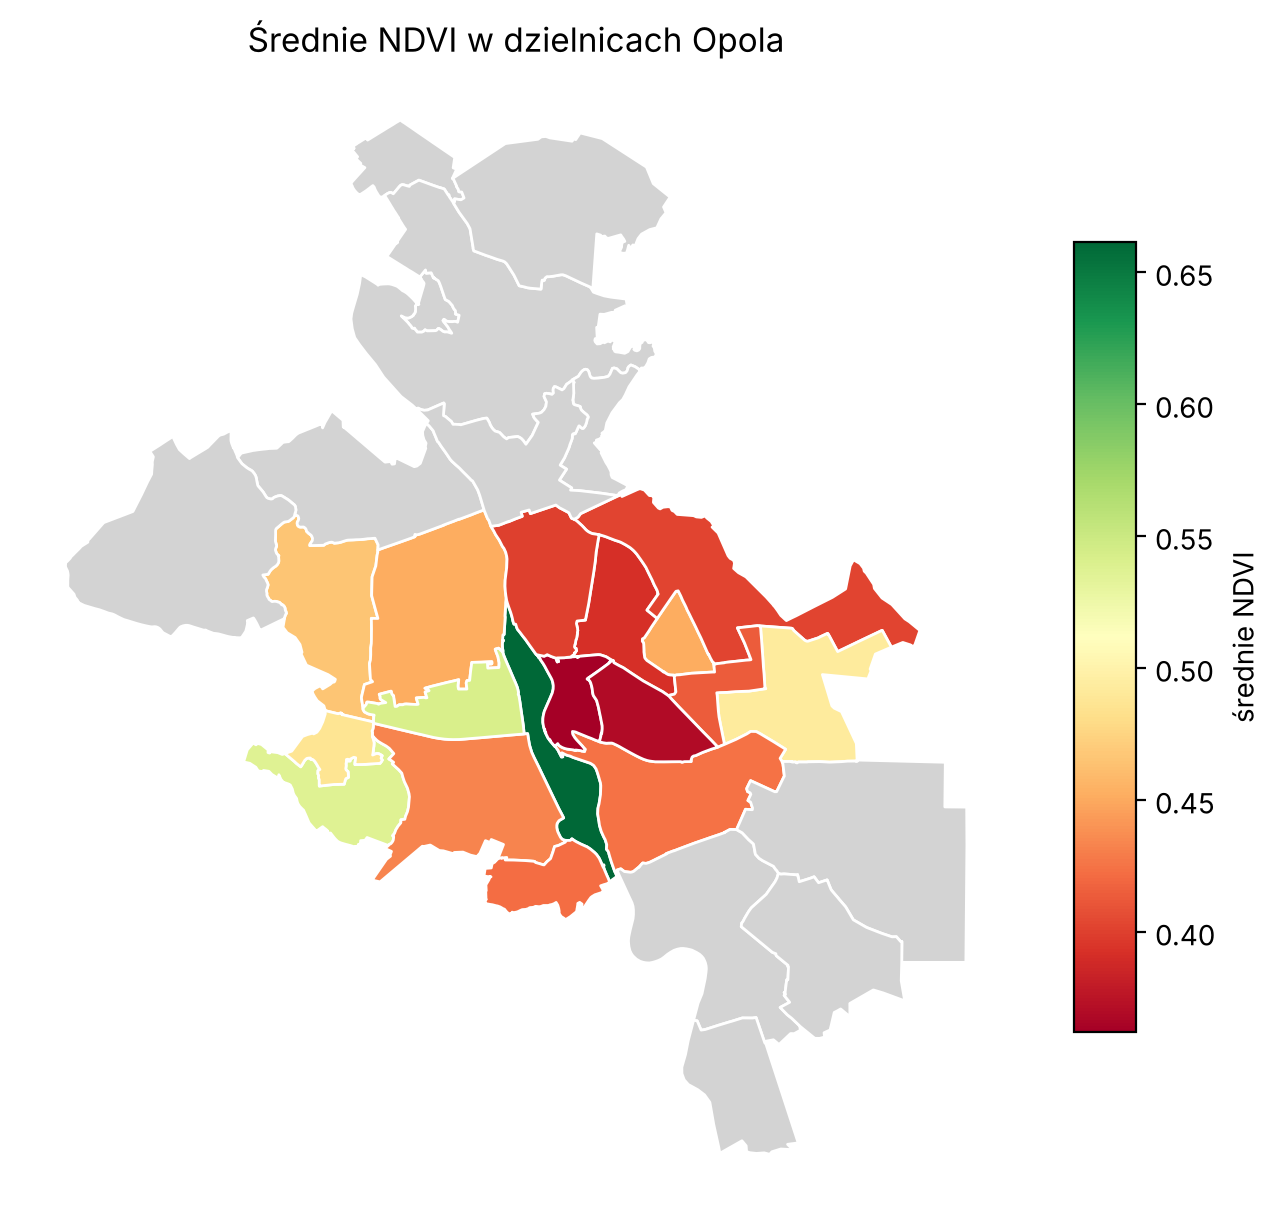

In [16]:
ndvi_districts = districts.merge(zonal, on="name")
ndvi_districts.loc[ndvi_districts["coverage"] < 0.9, "ndvi_mean"] = np.nan

ax = ndvi_districts.plot(column="ndvi_mean", cmap="RdYlGn", legend=True, edgecolor="white", figsize=(8, 8),
                         missing_kwds={"color": "lightgray", "label": "poza sceną / <90% pokrycia"},
                         legend_kwds={"label": "średnie NDVI"})
ax.set_title("Średnie NDVI w dzielnicach Opola"); ax.set_axis_off(); plt.show()

🤔 **Dlaczego nie bierzemy wszystkich dzielnic?** Wrzoski mają w scenie tylko ok. 5% powierzchni (sam skrawek lasu) i wyszłyby
na „najzieleńszą dzielnicę”. To ten sam problem co średnia z jednego czujnika w A7: mała i niereprezentatywna próbka.
Borki, Brzezie, Czarnowąsy, Grotowice i Świerkle leżą całkiem poza sceną, a `mask` rzuca dla nich `ValueError`.

### Bonus: zieleń a PM2.5 (część A + B)

11 dzielnic (≥90% pokrycia, ≥3 czujniki), korelacja Pearsona NDVI vs PM2.5: r = -0.20


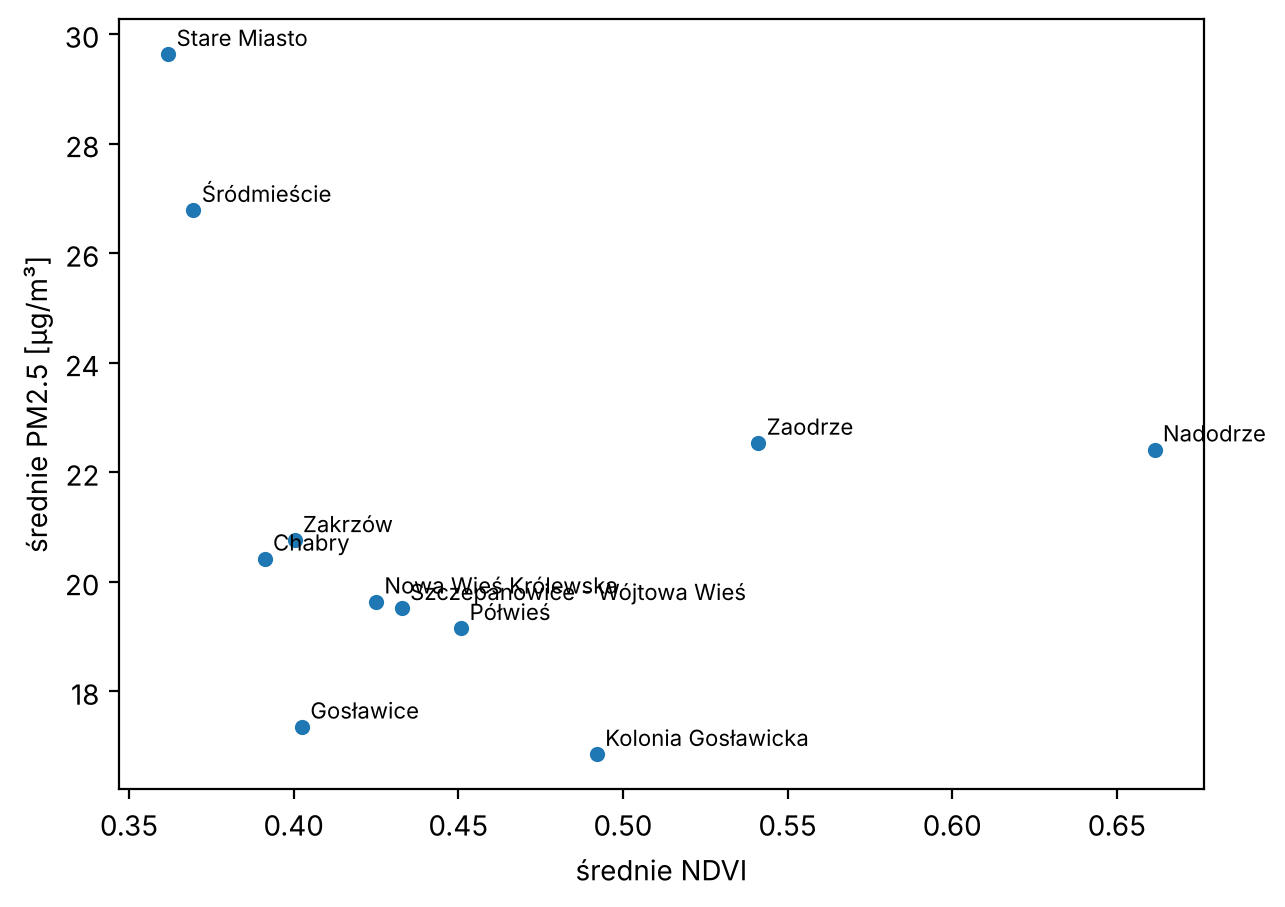

In [17]:
# średnie PM2.5 z części A (ten sam pipeline czyszczenia)
raw = pd.read_csv("dane/pm25_sensors.csv").drop_duplicates().dropna(subset=["lat", "lon"])
sw = raw["lat"].between(14, 24.5) & raw["lon"].between(49, 55)
raw.loc[sw, ["lat", "lon"]] = raw.loc[sw, ["lon", "lat"]].to_numpy()
raw = raw[raw["pm25"] >= 0]
sensors = gpd.GeoDataFrame(raw, geometry=gpd.points_from_xy(raw["lon"], raw["lat"]), crs="EPSG:4326").to_crs(DST_CRS)
pm = (gpd.sjoin(sensors, districts[["name", "geometry"]], predicate="within")
        .groupby("name").agg(pm25_mean=("pm25", "mean"), n=("pm25", "size")))

both = ranking.merge(pm, left_on="name", right_index=True)
both = both[both["n"] >= 3]
r = both["ndvi_mean"].corr(both["pm25_mean"])
print(f"{len(both)} dzielnic (≥90% pokrycia, ≥3 czujniki), korelacja Pearsona NDVI vs PM2.5: r = {r:.2f}")

ax = both.plot.scatter(x="ndvi_mean", y="pm25_mean", figsize=(7, 5))
for _, rr in both.iterrows():
    ax.annotate(rr["name"], (rr["ndvi_mean"], rr["pm25_mean"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("średnie NDVI"); ax.set_ylabel("średnie PM2.5 [µg/m³]"); plt.show()

💡 Na krańcach się zgadza: najmniej zielone dzielnice (Stare Miasto, Śródmieście) to te same, które w części A miały najgorsze
powietrze. Ogólnie zależność jest jednak **słaba** (r ≈ −0,2 na 11 dzielnicach, np. zielone Zaodrze ma średnio wysokie PM2.5).
Poza tym to **korelacja, nie przyczynowość**: centrum ma jednocześnie mało zieleni oraz dużo ruchu i zabudowy, a dane PM2.5 są syntetyczne.

## B9. Zapis wyniku do GeoTIFF

In [18]:
from pathlib import Path

out = Path("wyniki"); out.mkdir(exist_ok=True)

ndvi_profile = profile | {"compress": "deflate", "tiled": True, "blockxsize": 256, "blockysize": 256}
with rasterio.open(out / "ndvi_opole_2180.tif", "w", **ndvi_profile) as dst:
    dst.write(ndvi.astype("float32"), 1)
    dst.set_band_description(1, "NDVI (B08-B04)/(B08+B04), S2 L2A 2026-10-06")

cls_profile = ndvi_profile | {"dtype": "uint8", "nodata": 0}
with rasterio.open(out / "ndvi_classes_2180.tif", "w", **cls_profile) as dst:
    dst.write(classes, 1)
    dst.write_colormap(1, {0: (0, 0, 0, 0), **{i + 1: tuple(int(c[j:j + 2], 16) for j in (1, 3, 5)) + (255,)
                                              for i, c in enumerate(colors)}})

zonal.to_csv(out / "ndvi_districts.csv", index=False)

In [19]:
with rasterio.open(out / "ndvi_opole_2180.tif") as chk:
    a = chk.read(1)
    print(chk.crs, chk.res, chk.shape, chk.nodata, chk.descriptions)
    print("identyczne z pamięcią:", np.array_equal(a, ndvi, equal_nan=True))
print({p.name: f"{p.stat().st_size / 1e6:.1f} MB" for p in out.iterdir()})

EPSG:2180 (10.0, 10.0) (921, 1279) nan ('NDVI (B08-B04)/(B08+B04), S2 L2A 2026-10-06',)
identyczne z pamięcią: True
{'pm25.gpkg': '0.2 MB', 'ndvi_districts.csv': '0.0 MB', 'pm25_districts.geojson': '0.1 MB', 'ndvi_opole_2180.tif': '4.0 MB', 'ndvi_classes_2180.tif': '0.1 MB'}


Otwórz `wyniki/ndvi_opole_2180.tif` w QGIS razem z `wyniki/pm25.gpkg` z części A. Obie warstwy są w EPSG:2180, więc nakładają się bez reprojekcji „w locie”.

## Podsumowanie części B
`rasterio.open → metadane (crs, transform, nodata) → read → reproject na wspólną siatkę metryczną → algebra map (NDVI)
→ klasyfikacja i hektary → mask (statystyki strefowe) → zapis GeoTIFF`.